# Method 4: Optimal transport
Instead of predicting each player, move the whole *distribution* of low-minute profiles onto the distribution of full-season profiles.

The reference distribution is the training players' full-season profiles. Like KNN, OT is fit **per minutes bucket** (6 buckets, one prefix per training player-season) so the source distribution has the right noise level. Three variants:

| Variant | What is transported |
|---|---|
| `ot_1d` | each stat on its own: a value goes to the full-season value at the same percentile |
| `ot_joint` | the whole stat vector at once (Sinkhorn); each player gets the coupling-weighted mean of reference profiles |
| `ot_group` | one Sinkhorn transport per stat group in `wyscout/STAT_GROUPS.md`, then recombined; each stat sits in exactly one group |

The Sinkhorn entropy `reg` is chosen on training rows only. Note: OT matches distributions, not individuals, so it does not minimize per-player error the way a regression does. Normalizing the source by minutes bin (as the ridge does) was tried and changed the OT results very little, so it is not used.

**Setup shared by every method.** One model per gender and position group, trained on every per-game prefix (the player's first k matches, up to 750 minutes) of the 900+ minute player-seasons, each with its full-season per-90 as the target. The same fitted model handles any number of minutes. Rates, ratios and percents are never estimated: they are rebuilt from the estimated per-90 volumes.

In [1]:
%matplotlib inline
import sys, pathlib, warnings
warnings.filterwarnings("ignore")
# make the repo root importable no matter which folder the notebook is opened from
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "low_minute_player_analysis").is_dir())
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from low_minute_player_analysis import notebook_helpers as nh
from low_minute_player_analysis import reconstruct_methods as rm
from low_minute_player_analysis import temporal_methods as tm
from low_minute_player_analysis import reconstruction_eval as ev

nh.apply_style()
r = nh.load_results("results")         # out-of-fold scores for every group, gender and method
V, R = nh.volume(r), nh.rates(r)       # volume stats / rates rebuilt from the estimated volumes
P = nh.load_paired("results")          # paired differences vs the final ridge, with bootstrap intervals
nh.describe(r)
print("Sinkhorn reg grid:", rm.SINKHORN_REGS, "| rows used to pick reg / as reference:", rm.OT_FIT_ROWS, "/", rm.OT_REF_ROWS)

79,101 scored rows | genders ['female', 'male'] | 7 groups | checkpoints [np.int64(250), np.int64(500), np.int64(750)] | methods ['raw', 'shrink', 'ridge', 'knn', 'ot_1d', 'ot_joint', 'ot_group', 'kalman', 'kalman_blend', 'ridge_kalman', 'gru']
volume stats scored: 113 | rebuilt rates scored: 74
Sinkhorn reg grid: [0.002, 0.005, 0.01, 0.02, 0.05, 0.1] | rows used to pick reg / as reference: 500 / 1500


## 1. Results across all 14 gender / position-group sets

**How to read the numbers.** `nrmse` is the RMSE of the estimate against the player's true full-season
per-90, divided by the standard deviation of that true value. 0 is perfect; 1 means no better than guessing
the group average. Every table shows the **median over stats** (and over groups/genders unless stated).
The three columns / x positions are **minutes bins** of the sample the estimate was made from: 250 = 0-375 minutes,
500 = 375-625, 750 = 625-750 (every per-game prefix of a held-out player is scored; each player-season counts once
per bin). Scores are out-of-fold: the 5 folds split players, so nobody is predicted by a model that saw them.

method,raw,ot_1d,ot_joint,ot_group
checkpoint,,,,
250,1.489,0.899,0.861,0.837
500,0.713,0.611,0.735,0.629
750,0.518,0.480,0.678,0.535


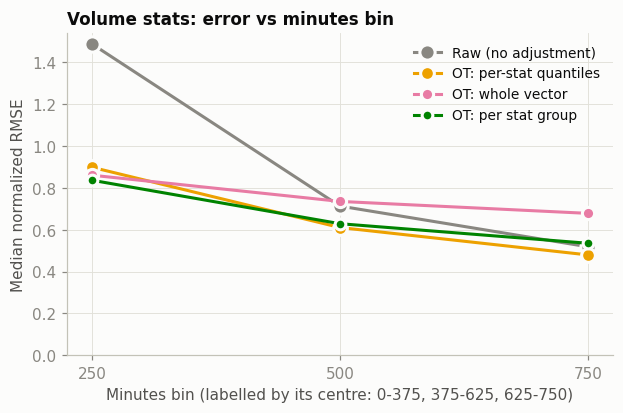

method,ot_1d (% reduction),ot_joint (% reduction),ot_group (% reduction)
checkpoint,,,
250,40.1,42.3,44.1
500,13.9,-1.4,12.4
750,7.5,-26.5,-0.0


In [2]:
METHODS = ["raw", "ot_1d", "ot_joint", "ot_group"]
summary = nh.median_nrmse(V, METHODS)
display(summary.round(3))
nh.curve_plot(summary, METHODS, "Volume stats: error vs minutes bin")
plt.show()
display(nh.improvement_table(V, METHODS[1:]).mul(100).round(1).add_suffix(" (% reduction)"))

Error reduction versus raw by position group, for each variant:

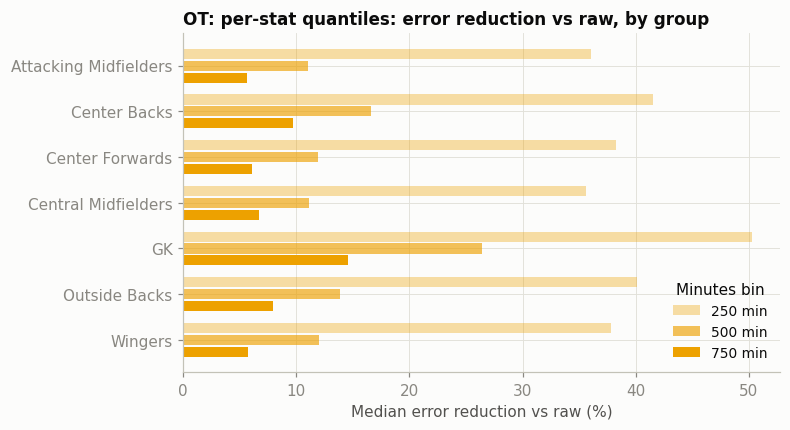

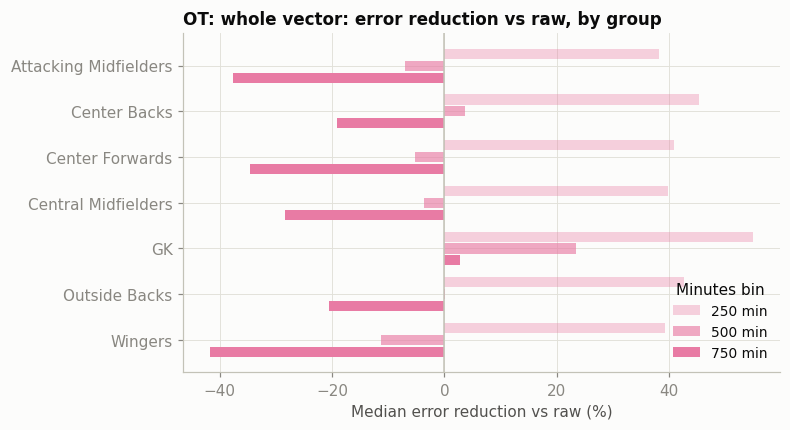

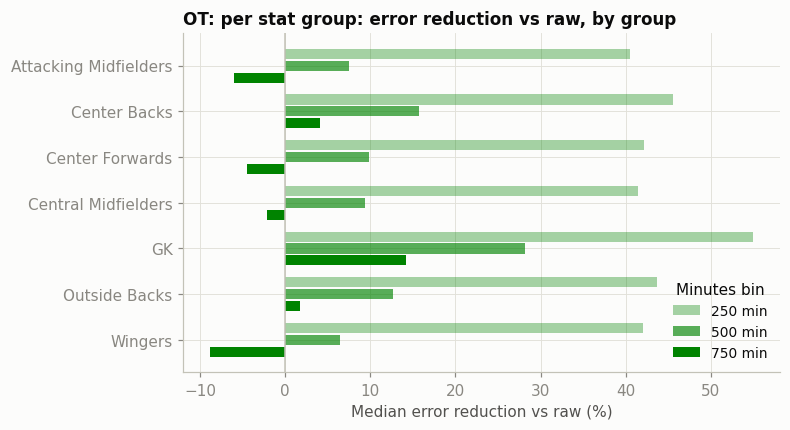

In [3]:
for m in METHODS[1:]:
    nh.group_bars(nh.improvement_by_group(V, m), m, f"{nh.LABELS[m]}: error reduction vs raw, by group")
    plt.show()

### Rates rebuilt from the estimated volumes

In [4]:
display(nh.median_nrmse(R, METHODS).round(3).rename_axis("minutes bin"))
display(nh.rate_table(R, METHODS, cp=500).round(3))
display(nh.missing_table(R, METHODS).round(4))

method,raw,ot_1d,ot_joint,ot_group
minutes bin,,,,
250,1.737,1.015,0.938,0.911
500,0.838,0.719,0.874,0.765
750,0.610,0.566,0.840,0.689


method,raw,ot_1d,ot_joint,ot_group
stat_type,,,,
rate_api_approx,0.844,0.766,0.870,0.798
rate_api_exact,1.031,0.906,0.980,0.902
rate_derived,0.754,0.638,0.797,0.680


,n_truth_ok,n_est_missing,n_compared,est_missing_share
method,,,,
raw,17532604,1039980,16492624,0.0593
ot_1d,17532604,329083,17203521,0.0188
ot_joint,17532604,166812,17365792,0.0095
ot_group,17532604,160012,17372592,0.0091


## 2. Worked example: male Wingers (live run)
This re-runs the method out-of-fold on one group so every step below is reproducible here (the full results above came from `reconstruction_eval.py`).

raw       median nrmse @250/500/750: [1.378, 0.627, 0.451]
ot_1d     median nrmse @250/500/750: [0.857, 0.546, 0.419]
ot_joint  median nrmse @250/500/750: [0.868, 0.738, 0.673]
ot_group  median nrmse @250/500/750: [0.816, 0.613, 0.511]


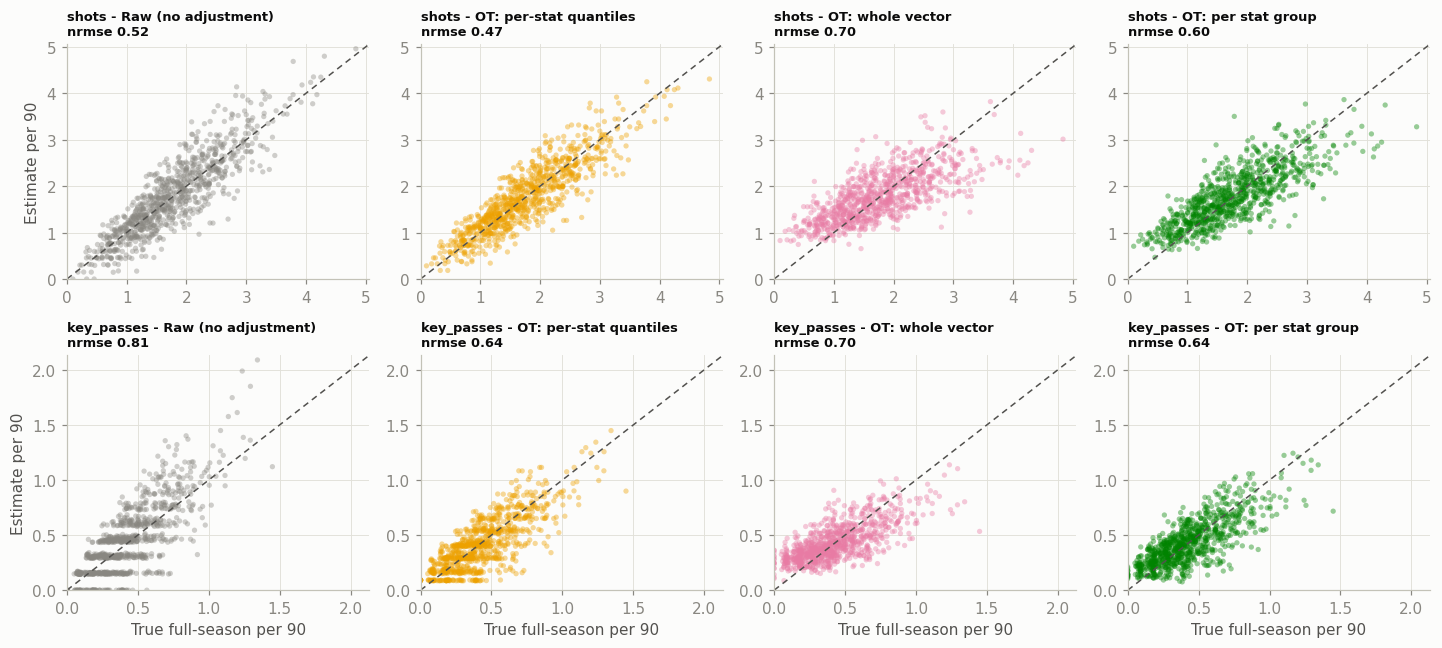

In [5]:
METHODS_DEMO = ["raw", "ot_1d", "ot_joint", "ot_group"]
pool, stems, est = nh.demo_group("male", "Wingers", METHODS_DEMO)
for m in METHODS_DEMO:
    print(f"{m:9s} median nrmse @250/500/750:",
          [round(float(nh.nrmse_per_stat(pool, est[m], b).median()), 3) for b in (250, 500, 750)])
fig = nh.scatter_grid(pool, est, ["shots", "key_passes"], 500, METHODS_DEMO)
plt.show()

### Diagnostic 1: the per-stat quantile map (`ot_1d`)
A low-minute value maps to the full-season value at the same percentile (training rows of the bucket that holds 500 minutes). Many low-minute samples are exactly 0 (no shot yet), and ties are given the middle of their rank, so all those players get one common value.

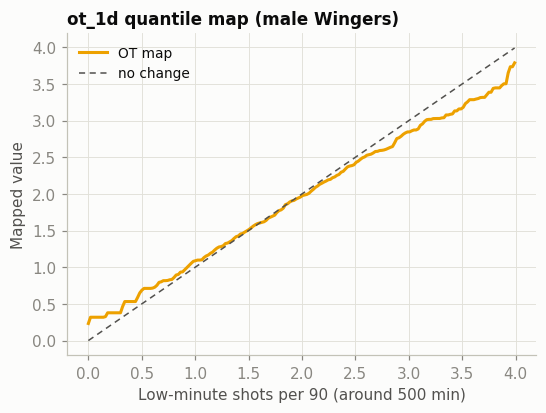

In [6]:
b = int(rm.bucket_of(np.array([500.0]))[0])
Tb = rm.bucket_training_rows(pool)
Tc = Tb[Tb["checkpoint"] == b]
s = "shots"
grid = np.linspace(0, Tc[f"low_{s}"].quantile(0.99), 200)
u = rm.middle_rank(grid, Tc[f"low_{s}"].to_numpy())
mapped = np.quantile(Tc[f"full_{s}"].to_numpy(), np.clip(u, 0, 1))
fig, ax = plt.subplots(figsize=(5.5, 3.8))
ax.plot(grid, mapped, color=nh.COLORS["ot_1d"], lw=2, label="OT map")
ax.plot(grid, grid, color=nh.INK2, lw=1, ls=(0, (4, 3)), label="no change")
ax.set_xlabel(f"Low-minute {s} per 90 (around 500 min)"); ax.set_ylabel("Mapped value")
ax.set_title("ot_1d quantile map (male Wingers)", loc="left"); ax.legend(); plt.show()

### Diagnostic 2: which `reg` did the training rows pick?
Smaller `reg` = a sharper (more individual) coupling; larger = more blur toward the average profile. One fold, the 500 bucket.

In [7]:
stems_, folds = ev.group_setup("male", "Wingers")
te = pool["player_id"].isin(folds[0])
T, E = pool[~te], pool[te]
E = E[E["bin"] == 500]
cache = {}
rm.ot_joint(T, E, stems, cache)
rm.ot_group(T, E, stems, cache)
regs = pd.Series({k[0].removeprefix("reg_"): v for k, v in cache.items() if isinstance(k, tuple)}, name="chosen reg")
display(regs.to_frame())

,chosen reg
joint,0.005
Shooting,0.005
Chance Creation,0.005
Passing,0.002
Progression,0.002
Dribbling,0.002
Duels,0.002
Aerial,0.005
Defending,0.002
Pressing & Recovery,0.005


### Strengths and limits
- Matches the *shape* of the high-minute distribution, including the spread that shrinkage removes.
- Per-player RMSE is worse than a regression's. Transport assigns a player the value at their rank, not the best guess for them.
- Splitting by stat group (`ot_group`) beats one joint transport: fewer dimensions means a more reliable coupling.
- The OT numbers used capped sample sizes (see the setup cell), which may make them slightly noisier.